<a href="https://colab.research.google.com/github/pari00720/Data-Analysis-using-Python-on-Netflix-dataset/blob/main/Task1%2C2%2C3%2C4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------- Global configuration (edit here only) ----------
RAW_FILE      = "Dataset.csv"                    # input file
CLEAN_FILE    = "cleaned_netflix_dataset.csv"    # Task 1 output / Task 2-4 input
PLACEHOLDERS  = ["not given", "unknown", "n/a", "na", "none", "null", "nan", ""]
TREND_START   = 1990                             # first year shown on the Task 4 chart
NETFLIX_RED   = "#E50914"
NETFLIX_DARK  = "#221F1F"
PALETTE_TYPE  = {"Movie": NETFLIX_RED, "TV Show": NETFLIX_DARK}

# ---------- Global plotting style ----------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ---------- Colab detection ----------
try:
    from google.colab import files   # only exists inside Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def ensure_file(path: str) -> str:
    """Return a valid path to `path`; in Colab, prompt an upload if it is missing."""
    if os.path.exists(path):
        return path
    if IN_COLAB:
        print(f"'{path}' not found. Please upload it now...")
        uploaded = files.upload()                      # opens the Colab upload dialog
        if not uploaded:
            raise FileNotFoundError(f"No file uploaded; '{path}' is required.")
        return list(uploaded.keys())[0]                # name of the uploaded file
    raise FileNotFoundError(f"'{path}' not found in {os.getcwd()}")


def load_csv(path: str) -> pd.DataFrame:
    """Read a CSV with explicit error handling for the most common failure modes."""
    try:
        df = pd.read_csv(ensure_file(path))
    except pd.errors.EmptyDataError:
        raise ValueError(f"'{path}' is empty.")
    except pd.errors.ParserError as exc:
        raise ValueError(f"'{path}' could not be parsed: {exc}")
    if df.empty:
        raise ValueError(f"'{path}' contains no rows.")
    return df


def require_columns(df: pd.DataFrame, cols: list) -> None:
    """Fail early, with a clear message, if expected columns are missing."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"Missing required column(s): {missing}")


print(f"Environment ready | pandas {pd.__version__} | Colab: {IN_COLAB}")

Environment ready | pandas 2.2.3 | Colab: True


In [ ]:
# ---- Load raw data ----
df_raw = load_csv(RAW_FILE)
require_columns(df_raw, ["show_id", "type", "title", "country", "release_year", "rating"])

print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")

# First 5 rows
display(df_raw.head())

# Column dtypes and non-null counts
print("\n--- DataFrame info ---")
df_raw.info()

# Standard missing values (true NaN)
print("\n--- Missing values (NaN) per column ---")
print(df_raw.isnull().sum())

# Hidden missing values: text placeholders such as "Not Given"
print("\n--- Hidden placeholders per text column (e.g. 'Not Given') ---")
text_cols = df_raw.select_dtypes(include=["object", "string"]).columns
hidden = {
    col: int(df_raw[col].astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum())
    for col in text_cols if col not in ("title", "show_id")   # titles can legitimately read "Unknown"
}
print(pd.Series(hidden).loc[lambda s: s > 0].to_string() or "None found")

'Dataset.csv' not found. Please upload it now...


Saving Dataset.csv to Dataset.csv
Shape: 8,790 rows x 10 columns



,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



--- DataFrame info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

--- Missing values (NaN) per column ---
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

--- Hidden placeholders per text column (e.g. 'Not Given') ---
director    258

In [ ]:
df = df_raw.copy()   # always work on a copy so the raw data stays untouched

# 2a. Strip whitespace first so placeholders like " Not Given " are recognised
str_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in str_cols:
    df[col] = df[col].astype("string").str.strip()          # remove leading/trailing spaces

# 2b. Convert placeholder text to real NaN so pandas can treat it as missing.
# `title` and `show_id` are skipped: a real film is titled "Unknown" (2011), so masking would delete valid data.
for col in [c for c in str_cols if c not in ("title", "show_id")]:
    df[col] = df[col].mask(df[col].str.lower().isin(PLACEHOLDERS), pd.NA)   # mask(): replace where condition is True

# 2c. Drop rows missing essential identifiers
essential = ["title", "type", "release_year"]
before = len(df)
df = df.dropna(subset=essential)                              # dropna(subset=...) only checks listed columns
print(f"Rows dropped for missing essential fields: {before - len(df)}")

# 2d. Impute descriptive text fields
df["director"] = df["director"].fillna("Unknown")
df["country"]  = df["country"].fillna("Unknown")
df["rating"]   = df["rating"].fillna("Not Rated")
if "listed_in" in df.columns:
    df["listed_in"] = df["listed_in"].fillna("Unknown")
if "duration" in df.columns:
    df["duration"] = df["duration"].fillna("Unknown")

# 2e. Parse dates; errors="coerce" turns unparseable values into NaT instead of crashing
if "date_added" in df.columns:
    df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

# 2f. Enforce a clean integer year
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df = df.dropna(subset=["release_year"]).astype({"release_year": "int64"})

print("\nMissing values after treatment:")
print(df.isnull().sum())

Rows dropped for missing essential fields: 0

Missing values after treatment:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [ ]:
# 3a. Collapse repeated internal spaces (e.g. "United  States" -> "United States")
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.replace(r"\s+", " ", regex=True).str.strip()

# 3b. Remove duplicates.
# `show_id` is a unique key, so a repeated title can carry a different ID.
# Compare on every column EXCEPT show_id to catch these hidden duplicates.
content_cols = [c for c in df.columns if c != "show_id"]
n_exact = int(df.duplicated().sum())                         # fully identical rows
n_hidden = int(df.duplicated(subset=content_cols).sum())     # identical apart from show_id
print(f"Exact duplicate rows            : {n_exact}")
print(f"Duplicates ignoring show_id     : {n_hidden}")

before = len(df)
df = df.drop_duplicates(subset=content_cols, keep="first").reset_index(drop=True)
print(f"Rows removed: {before - len(df)} | Rows remaining: {len(df):,}")

# 3c. Confirm show_id is still unique
assert df["show_id"].is_unique, "show_id contains duplicates after cleaning!"

Exact duplicate rows            : 0
Duplicates ignoring show_id     : 4
Rows removed: 4 | Rows remaining: 8,786


In [ ]:
# ---- type: map every spelling variant to exactly two labels ----
type_map = {
    "movie": "Movie", "movies": "Movie",
    "tv show": "TV Show", "tv shows": "TV Show", "tvshow": "TV Show", "tv series": "TV Show",
}
df["type"] = df["type"].str.lower().map(type_map).fillna(df["type"].str.title())

# ---- rating: upper-case so "tv-ma" / "TV-MA" collapse into one category ----
df["rating"] = df["rating"].str.upper().replace({"NOT RATED": "Not Rated"})

# ---- country: consistent title-case + fix common abbreviations ----
country_alias = {
    "Usa": "United States", "U.S.": "United States", "Us": "United States",
    "Uk": "United Kingdom", "U.K.": "United Kingdom",
    "Uae": "United Arab Emirates",
}

def standardize_country(value: str) -> str:
    """Clean one cell, which may hold several comma-separated countries."""
    parts = [p.strip().title() for p in str(value).split(",") if p.strip()]
    parts = [country_alias.get(p, p) for p in parts]
    # drop repeats inside one cell while preserving order
    return ", ".join(dict.fromkeys(parts)) if parts else "Unknown"

df["country"] = df["country"].apply(standardize_country)

# ---- Validation ----
print("type values   :", sorted(df["type"].unique()))
print("rating values :", sorted(df["rating"].unique()))
print("country count :", df["country"].nunique(), "unique entries")
print("\nType distribution:")
print(df["type"].value_counts())

type values   : ['Movie', 'TV Show']
rating values : ['G', 'NC-17', 'NR', 'PG', 'PG-13', 'R', 'TV-14', 'TV-G', 'TV-MA', 'TV-PG', 'TV-Y', 'TV-Y7', 'TV-Y7-FV', 'UR']
country count : 86 unique entries

Type distribution:
type
Movie      6123
TV Show    2663
Name: count, dtype: int64


In [ ]:
# Final quality gate before saving
checks = {
    "No duplicate show_id":        df["show_id"].is_unique,
    "Only 2 content types":        set(df["type"].unique()) <= {"Movie", "TV Show"},
    "No missing essential fields": df[["title", "type", "release_year"]].notnull().all().all(),
}
for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
if not all(checks.values()):
    raise ValueError("Data quality checks failed. Review the cleaning steps above.")

try:
    df.to_csv(CLEAN_FILE, index=False)                       # index=False avoids an extra index column
    print(f"\nSaved '{CLEAN_FILE}' | {df.shape[0]:,} rows x {df.shape[1]} columns")
    if IN_COLAB:
        files.download(CLEAN_FILE)                           # download a copy to your computer
except OSError as exc:
    print(f"Could not save the file: {exc}")

# Cleaning summary for the report
print("\n=== TASK 1 CLEANING SUMMARY ===")
print(f"Raw rows            : {len(df_raw):,}")
print(f"Cleaned rows        : {len(df):,}")
print(f"Rows removed        : {len(df_raw) - len(df):,}")
print(f"Director = Unknown  : {(df['director'] == 'Unknown').sum():,}")
print(f"Country  = Unknown  : {(df['country'] == 'Unknown').sum():,}")

[PASS] No duplicate show_id
[PASS] Only 2 content types
[PASS] No missing essential fields

Saved 'cleaned_netflix_dataset.csv' | 8,786 rows x 10 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== TASK 1 CLEANING SUMMARY ===
Raw rows            : 8,790
Cleaned rows        : 8,786
Rows removed        : 4
Director = Unknown  : 2,587
Country  = Unknown  : 287


In [ ]:
# Step 1: reload from disk so this task is independent of earlier in-memory state
df2 = load_csv(CLEAN_FILE)
require_columns(df2, ["type"])

# Step 2: counts and percentages
type_counts = df2["type"].value_counts()                     # value_counts(): frequency of each category
type_pct    = df2["type"].value_counts(normalize=True) * 100 # normalize=True returns proportions
total_titles = int(type_counts.sum())

summary_type = pd.DataFrame({
    "Count": type_counts,
    "Percentage (%)": type_pct.round(2),
})
summary_type.loc["Total"] = [total_titles, round(float(type_pct.sum()), 2)]
summary_type["Count"] = summary_type["Count"].astype(int)      # keep counts as integers after adding the total row
display(summary_type)

,Count,Percentage (%)
type,,
Movie,6123,69.69
TV Show,2663,30.31
Total,8786,100.00


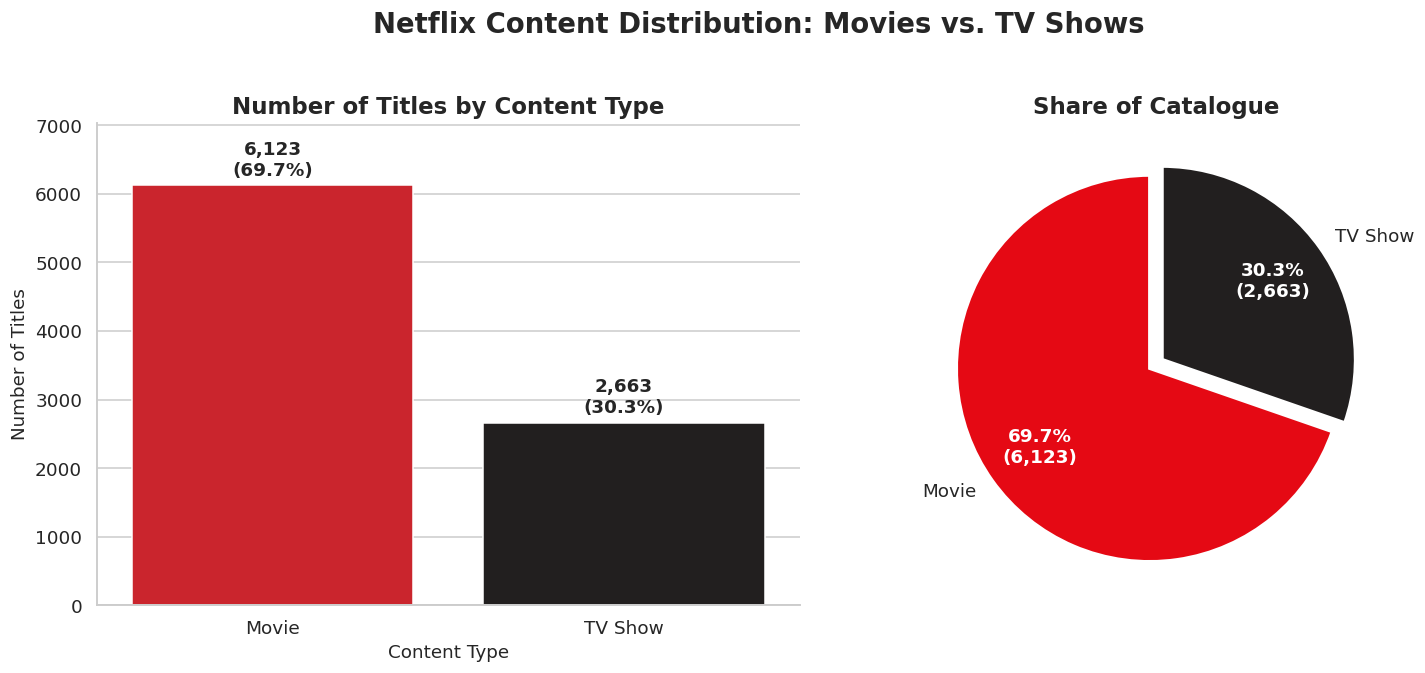

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Netflix Content Distribution: Movies vs. TV Shows",
             fontsize=18, fontweight="bold", y=1.02)

order = type_counts.index.tolist()                           # keep the same order in both charts
colors = [PALETTE_TYPE.get(t, "#888888") for t in order]

# ---- Left: styled count plot ----
ax = axes[0]
sns.countplot(data=df2, x="type", order=order, palette=colors, hue="type",
              legend=False, ax=ax)
ax.set_title("Number of Titles by Content Type")
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")
for bar, label in zip(ax.patches, order):                    # annotate each bar with count and share
    h = bar.get_height()
    ax.annotate(f"{int(h):,}\n({type_pct[label]:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, h),
                ha="center", va="bottom", fontsize=12, fontweight="bold",
                xytext=(0, 4), textcoords="offset points")
ax.set_ylim(0, type_counts.max() * 1.15)

# ---- Right: pie chart with annotations ----
ax = axes[1]
wedges, texts, autotexts = ax.pie(
    type_counts.values, labels=order, colors=colors, startangle=90,
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * total_titles / 100)):,})",
    pctdistance=0.7, explode=[0.04] * len(order),
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12},
)
for t in autotexts:
    t.set_color("white"); t.set_fontweight("bold")
ax.set_title("Share of Catalogue")

plt.tight_layout()
plt.savefig("task2_content_type_dashboard.png", bbox_inches="tight")   # high-resolution export
plt.show()

In [ ]:
# Step 4: numeric comparison of proportions
movies   = int(type_counts.get("Movie", 0))
tv_shows = int(type_counts.get("TV Show", 0))
if tv_shows == 0 or movies == 0:
    raise ValueError("Both Movie and TV Show records are required for comparison.")

ratio       = movies / tv_shows
gap_count   = movies - tv_shows
gap_pp      = float(type_pct["Movie"] - type_pct["TV Show"])   # percentage-point gap
relative_pct = (movies / tv_shows - 1) * 100

# Step 5: summary block
print("=" * 62)
print("TASK 2: KEY FINDINGS")
print("=" * 62)
print(f"Total titles analysed      : {total_titles:,}")
print(f"Movies                     : {movies:,}  ({type_pct['Movie']:.2f}%)")
print(f"TV Shows                   : {tv_shows:,}  ({type_pct['TV Show']:.2f}%)")
print("-" * 62)
print(f"Movie-to-TV-Show ratio     : {ratio:.2f} : 1")
print(f"Absolute gap               : {gap_count:,} titles")
print(f"Percentage-point gap       : {gap_pp:.2f} pp")
print(f"Movies exceed TV Shows by  : {relative_pct:.1f}% (relative)")
print("=" * 62)
print(f"""
Interpretation
 - Movies make up roughly {type_pct['Movie']:.0f}% of the catalogue, so for about every
   {ratio:.1f} movies there is 1 TV show.
 - TV Shows are fewer titles but each one holds viewers across multiple seasons,
   so title count understates their share of viewing time.
 - Count alone does not measure engagement; pair this with viewership data
   before drawing investment conclusions.
""")

TASK 2: KEY FINDINGS
Total titles analysed      : 8,786
Movies                     : 6,123  (69.69%)
TV Shows                   : 2,663  (30.31%)
--------------------------------------------------------------
Movie-to-TV-Show ratio     : 2.30 : 1
Absolute gap               : 3,460 titles
Percentage-point gap       : 39.38 pp
Movies exceed TV Shows by  : 129.9% (relative)

Interpretation
 - Movies make up roughly 70% of the catalogue, so for about every
   2.3 movies there is 1 TV show.
 - TV Shows are fewer titles but each one holds viewers across multiple seasons,
   so title count understates their share of viewing time.
 - Count alone does not measure engagement; pair this with viewership data
   before drawing investment conclusions.



Task 2 done , Task 3 started

In [ ]:
df3 = load_csv(CLEAN_FILE)
require_columns(df3, ["country", "type"])

# Step 1: split multi-country cells and explode into one row per country
df3["country"] = df3["country"].fillna("Unknown").astype(str)
country_df = (
    df3.assign(country=df3["country"].str.split(","))        # "A, B" -> ["A", "B"]
       .explode("country")                                   # one row per list element
       .assign(country=lambda d: d["country"].str.strip())   # clean leftover whitespace
)
country_df = country_df[country_df["country"] != ""]

n_multi = int(df3["country"].str.contains(",").sum())
print(f"Titles listing multiple countries : {n_multi:,}")
print(f"Rows after explode                : {len(country_df):,} (original titles: {len(df3):,})")

# Separate unknowns so they do not distort the ranking
unknown_n = int((country_df["country"] == "Unknown").sum())
known_df  = country_df[country_df["country"] != "Unknown"]
print(f"Titles with unknown country       : {unknown_n:,} ({unknown_n / len(df3) * 100:.1f}%) | excluded from ranking")

# Step 2: total count per country
country_counts = known_df["country"].value_counts()
print(f"\nDistinct countries represented    : {country_counts.shape[0]}")
display(country_counts.head(15).rename("Titles").to_frame())

Titles listing multiple countries : 0
Rows after explode                : 8,786 (original titles: 8,786)
Titles with unknown country       : 287 (3.3%) | excluded from ranking

Distinct countries represented    : 85


,Titles
country,
United States,3240
India,1056
United Kingdom,638
Pakistan,420
Canada,271
Japan,259
South Korea,214
France,213
Spain,182


In [ ]:
TOP_N = 10
top10 = country_counts.head(TOP_N).rename_axis("Country").reset_index(name="Titles")
top10["Share of Known (%)"]   = (top10["Titles"] / country_counts.sum() * 100).round(2)
top10["Cumulative Share (%)"] = top10["Share of Known (%)"].cumsum().round(2)
top10.index = top10.index + 1            # rank starts at 1
top10.index.name = "Rank"
display(top10)

# Content-type mix inside the top 10 (adds strategic depth)
mix = (
    known_df[known_df["country"].isin(top10["Country"])]
    .groupby(["country", "type"]).size().unstack(fill_value=0)   # groupby + unstack builds a pivot table
    .reindex(top10["Country"])
)
mix["TV Show share (%)"] = (mix.get("TV Show", 0) / mix.sum(axis=1) * 100).round(1)
print("\nContent mix in the top-10 countries:")
display(mix)

,Country,Titles,Share of Known (%),Cumulative Share (%)
Rank,,,,
1,United States,3240,38.12,38.12
2,India,1056,12.42,50.54
3,United Kingdom,638,7.51,58.05
4,Pakistan,420,4.94,62.99
5,Canada,271,3.19,66.18
6,Japan,259,3.05,69.23
7,South Korea,214,2.52,71.75
8,France,213,2.51,74.26
9,Spain,182,2.14,76.40



Content mix in the top-10 countries:


type,Movie,TV Show,TV Show share (%)
Country,,,
United States,2395,845,26.1
India,975,81,7.7
United Kingdom,387,251,39.3
Pakistan,71,349,83.1
Canada,187,84,31.0
Japan,87,172,66.4
South Korea,49,165,77.1
France,148,65,30.5
Spain,129,53,29.1


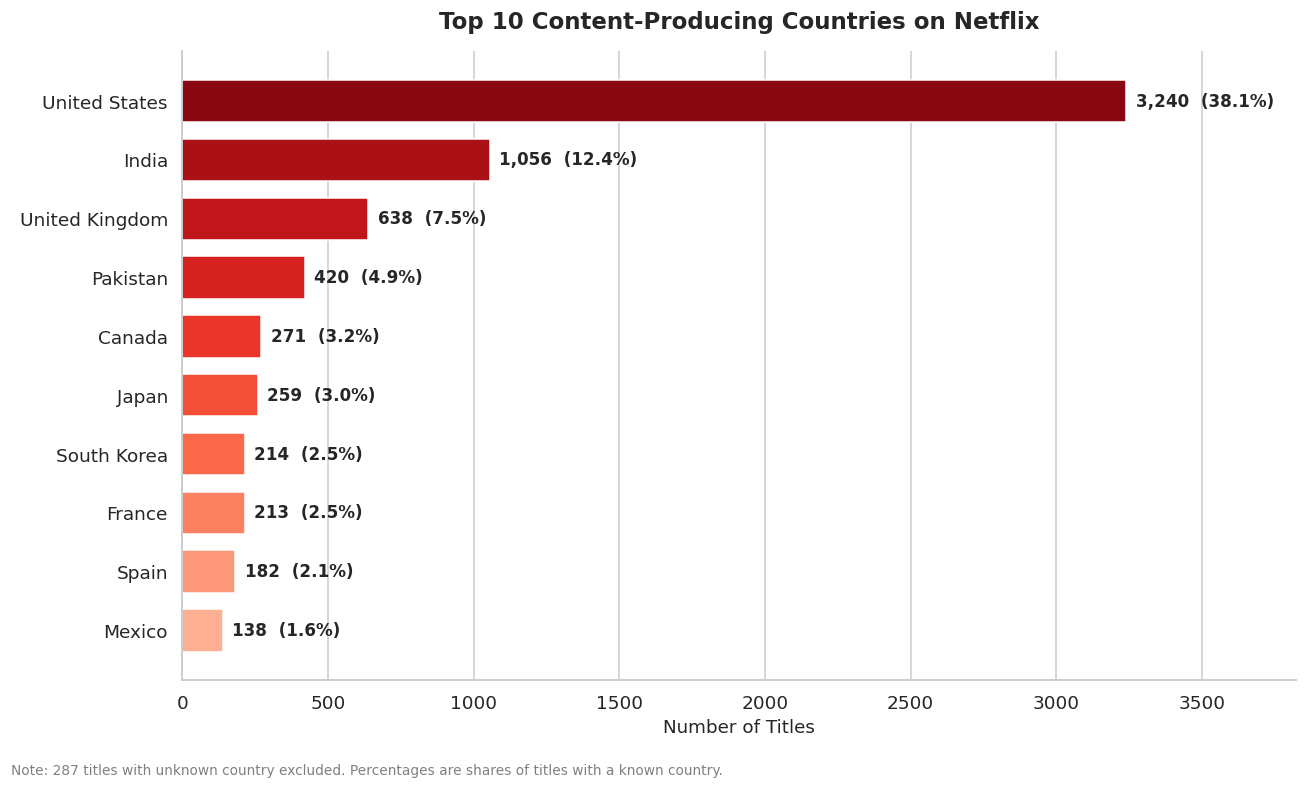

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
plot_df = top10.sort_values("Titles", ascending=True)        # ascending so the largest bar sits at the top

# Sequential palette: darker = more titles
colors = sns.color_palette("Reds", n_colors=len(plot_df) + 3)[3:]
bars = ax.barh(plot_df["Country"], plot_df["Titles"], color=colors,
               edgecolor="white", height=0.72)

# Value labels at the end of each bar
for bar, titles, share in zip(bars, plot_df["Titles"], plot_df["Share of Known (%)"]):
    ax.text(bar.get_width() + plot_df["Titles"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{titles:,}  ({share:.1f}%)", va="center", fontsize=11, fontweight="bold")

ax.set_title(f"Top {TOP_N} Content-Producing Countries on Netflix", pad=15)
ax.set_xlabel("Number of Titles")
ax.set_ylabel("")
ax.set_xlim(0, plot_df["Titles"].max() * 1.18)
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02,
         f"Note: {unknown_n:,} titles with unknown country excluded. Percentages are shares of titles with a known country.",
         fontsize=9, color="gray")

plt.tight_layout()
plt.savefig("task3_top10_countries.png", bbox_inches="tight")
plt.show()

In [ ]:
leader, leader_n = top10.iloc[0]["Country"], int(top10.iloc[0]["Titles"])
runner, runner_n = top10.iloc[1]["Country"], int(top10.iloc[1]["Titles"])
top3_share  = top10["Share of Known (%)"].head(3).sum()
top10_share = top10["Share of Known (%)"].sum()
long_tail   = country_counts.shape[0] - TOP_N

print("=" * 66)
print("TASK 3: STRATEGIC INSIGHTS")
print("=" * 66)
print(f"1. CONCENTRATION  : {leader} leads with {leader_n:,} titles, {leader_n / runner_n:.1f}x the next market ({runner}).")
print(f"2. TOP-3 SHARE    : The top 3 countries hold {top3_share:.1f}% of all titles with a known country.")
print(f"3. TOP-10 SHARE   : The top 10 hold {top10_share:.1f}%; the other {long_tail} countries share {100 - top10_share:.1f}%.")

asia = {"India", "Japan", "South Korea", "Pakistan"}
asia_in_top = [c for c in top10["Country"] if c in asia]
print(f"4. ASIAN MARKETS  : {len(asia_in_top)} of the top 10 are Asian ({', '.join(asia_in_top)}).")

tv_heavy = mix["TV Show share (%)"].sort_values(ascending=False)
print(f"5. FORMAT MIX     : Highest TV share: {tv_heavy.index[0]} ({tv_heavy.iloc[0]:.1f}%); "
      f"lowest: {tv_heavy.index[-1]} ({tv_heavy.iloc[-1]:.1f}%).")
print("=" * 66)
print("""
Business implications
 - Content strategy is heavily weighted toward a few markets. Dependence on one
   catalogue origin is a concentration risk if licensing costs or regulation shift.
 - Strong Asian representation (India, Pakistan, Japan, South Korea) suggests
   local-language content is a growth lever alongside US output. The mix differs
   by market: India is movie-led, while Pakistan, South Korea and Japan lean TV.
 - Countries with a high TV share can anchor subscriber retention (multi-season
   viewing); movie-heavy markets suit event releases and acquisition deals.
 - The long tail of small contributors is an opportunity for regional co-productions.
 - Caveat: this counts titles, not viewing hours or spend, and unknown-country
   titles are excluded.
""")

TASK 3: STRATEGIC INSIGHTS
1. CONCENTRATION  : United States leads with 3,240 titles, 3.1x the next market (India).
2. TOP-3 SHARE    : The top 3 countries hold 58.0% of all titles with a known country.
3. TOP-10 SHARE   : The top 10 hold 78.0%; the other 75 countries share 22.0%.
4. ASIAN MARKETS  : 4 of the top 10 are Asian (India, Pakistan, Japan, South Korea).
5. FORMAT MIX     : Highest TV share: Pakistan (83.1%); lowest: India (7.7%).

Business implications
 - Content strategy is heavily weighted toward a few markets. Dependence on one
   catalogue origin is a concentration risk if licensing costs or regulation shift.
 - Strong Asian representation (India, Pakistan, Japan, South Korea) suggests
   local-language content is a growth lever alongside US output. The mix differs
   by market: India is movie-led, while Pakistan, South Korea and Japan lean TV.
 - Countries with a high TV share can anchor subscriber retention (multi-season
   viewing); movie-heavy markets suit event rele

Taks 3 completed , Taks 4 started


In [ ]:
df4 = load_csv(CLEAN_FILE)
require_columns(df4, ["release_year", "type"])

df4["release_year"] = pd.to_numeric(df4["release_year"], errors="coerce")
df4 = df4.dropna(subset=["release_year"]).astype({"release_year": "int64"})

# Step 1-2: yearly counts, split by type
yearly = (
    df4.groupby(["release_year", "type"]).size()             # count rows per (year, type)
       .unstack(fill_value=0)                                # reshape: types become columns
)
# reindex over the FULL year range so years with zero releases show as 0 rather than disappearing
full_range = range(int(yearly.index.min()), int(yearly.index.max()) + 1)
yearly = yearly.reindex(full_range, fill_value=0)
for col in ["Movie", "TV Show"]:
    if col not in yearly.columns:
        yearly[col] = 0
yearly["Total"] = yearly["Movie"] + yearly["TV Show"]
yearly.index.name = "release_year"

print(f"Year range: {yearly.index.min()} to {yearly.index.max()}")
print("\nMost recent 12 years:")
display(yearly.tail(12))

Year range: 1925 to 2021

Most recent 12 years:


type,Movie,TV Show,Total
release_year,,,
2010,153,39,192
2011,145,40,185
2012,173,63,236
2013,225,61,286
2014,263,88,351
2015,396,159,555
2016,658,243,901
2017,765,265,1030
2018,766,378,1144


In [ ]:
# ---- Peak years ----
peak_total = int(yearly["Total"].idxmax())
peak_movie = int(yearly["Movie"].idxmax())
peak_tv    = int(yearly["TV Show"].idxmax())

# ---- Decade view: shows long-run growth without year-to-year noise ----
decade = yearly.copy()
decade["Decade"] = (decade.index // 10) * 10                 # floor-divide to get the decade start
decade_tbl = decade.groupby("Decade")[["Movie", "TV Show", "Total"]].sum()
decade_tbl["Growth vs prior decade (%)"] = (decade_tbl["Total"].pct_change() * 100).round(1)
decade_tbl.iloc[-1, decade_tbl.columns.get_loc("Growth vs prior decade (%)")] = np.nan   # latest decade is incomplete
print("Titles by decade of release (latest decade is incomplete, so its growth rate is not shown):")
display(decade_tbl.tail(8))

# ---- Recent trend: use the last COMPLETE year as the endpoint ----
latest_year   = int(yearly.index.max())
last_full     = latest_year - 1                              # latest year is likely partial
recent        = yearly.loc[last_full - 4:last_full]          # five-year window of complete years
prev_window   = yearly.loc[last_full - 9:last_full - 5]
recent_growth = (recent["Total"].sum() / prev_window["Total"].sum() - 1) * 100

# Compound annual growth rate, 2000 to last full year
base_year = 2000
def cagr(series):
    start, end, n = series.loc[base_year], series.loc[last_full], last_full - base_year
    return ((end / start) ** (1 / n) - 1) * 100 if start > 0 and n > 0 else float("nan")

cagr_movie, cagr_tv = cagr(yearly["Movie"]), cagr(yearly["TV Show"])

print("\n--- Peak years ---")
print(f"Overall peak : {peak_total} ({int(yearly.loc[peak_total, 'Total']):,} titles)")
print(f"Movie peak   : {peak_movie} ({int(yearly.loc[peak_movie, 'Movie']):,})")
print(f"TV Show peak : {peak_tv} ({int(yearly.loc[peak_tv, 'TV Show']):,})")
print("\n--- Recent trend ---")
print(f"{last_full - 4}-{last_full} vs {last_full - 9}-{last_full - 5}: {recent_growth:+.1f}% change in total titles")
print(f"CAGR {base_year}-{last_full}: Movies {cagr_movie:.1f}% | TV Shows {cagr_tv:.1f}%")
print(f"{latest_year} (partial year): {int(yearly.loc[latest_year, 'Total']):,} titles")
decline = (yearly.loc[last_full, "Total"] / yearly.loc[peak_total, "Total"] - 1) * 100
print(f"Change from peak ({peak_total}) to last full year ({last_full}): {decline:+.1f}%")

Titles by decade of release (latest decade is incomplete, so its growth rate is not shown):


type,Movie,TV Show,Total,Growth vs prior decade (%)
Decade,,,,
1950,11,0,11,-26.7
1960,23,2,25,127.3
1970,66,4,70,180.0
1980,122,7,129,84.3
1990,241,33,274,112.4
2000,677,130,807,194.5
2010,4176,1733,5909,632.2
2020,794,751,1545,NaN



--- Peak years ---
Overall peak : 2018 (1,144 titles)
Movie peak   : 2018 (766)
TV Show peak : 2020 (436)

--- Recent trend ---
2016-2020 vs 2011-2015: +213.5% change in total titles
CAGR 2000-2020: Movies 14.7% | TV Shows 26.4%
2021 (partial year): 592 titles
Change from peak (2018) to last full year (2020): -16.7%


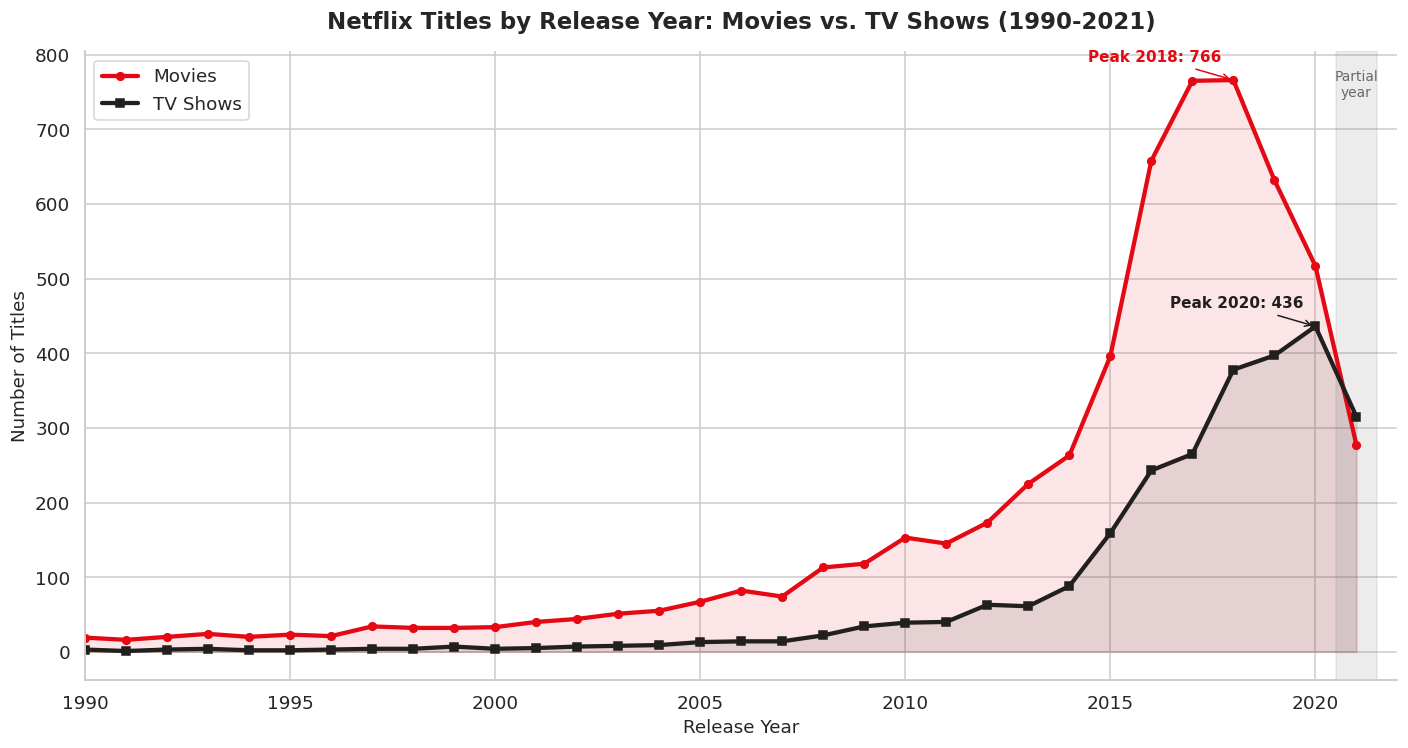

In [ ]:
trend = yearly.loc[TREND_START:]          # slice to a readable window; pre-1990 years hold few titles

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(trend.index, trend["Movie"],   color=NETFLIX_RED,  linewidth=2.8, marker="o", markersize=5, label="Movies")
ax.plot(trend.index, trend["TV Show"], color=NETFLIX_DARK, linewidth=2.8, marker="s", markersize=5, label="TV Shows")
ax.fill_between(trend.index, trend["Movie"],   alpha=0.10, color=NETFLIX_RED)
ax.fill_between(trend.index, trend["TV Show"], alpha=0.10, color=NETFLIX_DARK)

# Peak annotations
for col, color, peak in [("Movie", NETFLIX_RED, peak_movie), ("TV Show", NETFLIX_DARK, peak_tv)]:
    if peak in trend.index:
        y = trend.loc[peak, col]
        ax.annotate(f"Peak {peak}: {int(y):,}", xy=(peak, y), xytext=(-95, 12),
                    textcoords="offset points", fontsize=10, fontweight="bold", color=color,
                    arrowprops=dict(arrowstyle="->", color=color))

# Flag the likely-incomplete final year
ax.axvspan(latest_year - 0.5, latest_year + 0.5, color="gray", alpha=0.15)
ax.text(latest_year, ax.get_ylim()[1] * 0.97, "Partial\nyear", ha="center", va="top", fontsize=9, color="dimgray")

ax.set_title(f"Netflix Titles by Release Year: Movies vs. TV Shows ({TREND_START}-{latest_year})", pad=15)
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")
ax.set_xlim(TREND_START, latest_year + 1)
ax.legend(frameon=True, loc="upper left", fontsize=12)

plt.tight_layout()
plt.savefig("task4_release_year_trend.png", bbox_inches="tight")
plt.show()

In [ ]:
tv_share_recent = recent["TV Show"].sum() / recent["Total"].sum() * 100
tv_share_early  = yearly.loc[2000:2009, "TV Show"].sum() / yearly.loc[2000:2009, "Total"].sum() * 100

print("=" * 68)
print("TASK 4: KEY TAKEAWAYS")
print("=" * 68)
print(f"1. PEAK            : Production peaks in {peak_total} ({int(yearly.loc[peak_total, 'Total']):,} titles).")
print(f"2. LONG-TERM GROWTH: Output rose from {int(yearly.loc[1990:1999, 'Total'].sum()):,} titles (1990s) "
      f"to {int(yearly.loc[2010:2019, 'Total'].sum()):,} (2010s).")
print(f"3. FORMAT SHIFT    : TV Show share of releases moved from {tv_share_early:.1f}% (2000s) "
      f"to {tv_share_recent:.1f}% ({last_full - 4}-{last_full}).")
print(f"4. RECENT MOMENTUM : {recent_growth:+.1f}% change versus the prior five-year window.")
print(f"5. GROWTH RATES    : CAGR since {base_year}: Movies {cagr_movie:.1f}%, TV Shows {cagr_tv:.1f}%.")
print(f"6. POST-PEAK       : Total releases are {decline:+.1f}% versus the peak by {last_full}.")
print("=" * 68)
print("""
Business interpretation
 - The catalogue is dominated by recent releases, consistent with a strategy of
   prioritising fresh content over deep back-catalogue licensing.
 - Growth accelerates sharply in the 2010s, which is consistent with Netflix's
   streaming scale-up and push into originals (the data shows the pattern, not the cause).
 - Movie releases fall after their peak while TV releases hold up, so the mix is
   tilting toward series. Whether the post-peak dip is real or reflects recent
   titles not yet added to the catalogue cannot be determined from this file.
 - A rising TV share signals a deliberate bet on serialised content, which tends to
   support retention better than one-off films.
 - Any dip in the final year(s) reflects partial-year data and the lag between
   production and release, not necessarily a real slowdown.
 - Caveat: release_year is the original release year. To study Netflix's own
   acquisition cadence, repeat this analysis on the year from `date_added`.
""")

TASK 4: KEY TAKEAWAYS
1. PEAK            : Production peaks in 2018 (1,144 titles).
2. LONG-TERM GROWTH: Output rose from 274 titles (1990s) to 5,909 (2010s).
3. FORMAT SHIFT    : TV Show share of releases moved from 16.1% (2000s) to 34.0% (2016-2020).
4. RECENT MOMENTUM : +213.5% change versus the prior five-year window.
5. GROWTH RATES    : CAGR since 2000: Movies 14.7%, TV Shows 26.4%.
6. POST-PEAK       : Total releases are -16.7% versus the peak by 2020.

Business interpretation
 - The catalogue is dominated by recent releases, consistent with a strategy of
   prioritising fresh content over deep back-catalogue licensing.
 - Growth accelerates sharply in the 2010s, which is consistent with Netflix's
   streaming scale-up and push into originals (the data shows the pattern, not the cause).
 - Movie releases fall after their peak while TV releases hold up, so the mix is
   tilting toward series. Whether the post-peak dip is real or reflects recent
   titles not yet added to the cata

all tasks done
